#  Proses 1 (EDA & Preprocessing) dan Proses 2 (Clustering)

Notebook ini disusun berurutan dari pemeriksaan data hingga clustering. Setiap cell memiliki penjelasan singkat tentang tujuan dan alasan langkah tersebut.

**Proses 1:** Exploratory Data Analysis (EDA) dan data preprocessing.  
**Proses 2:** Clustering menggunakan K-Means dan DBSCAN.


## PROSES 1 — EDA DAN DATA PREPROCESSING

### Cell 1. Import library dan konfigurasi
Cell ini memuat pustaka untuk manipulasi data, visualisasi, preprocessing, dan clustering. RANDOM_STATE menjaga hasil eksperimen tetap konsisten.

In [11]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.neighbors import NearestNeighbors

RANDOM_STATE = 42
TRAIN_PATH = Path("data/trainingData.csv")
VALIDATION_PATH = Path("data/validationData.csv")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

TARGET_COLS = ["BUILDINGID", "FLOOR", "LONGITUDE", "LATITUDE"]
METADATA_COLS = ["USERID", "PHONEID", "TIMESTAMP"]

### Cell 2. Membaca dataset
Cell ini memuat data training. Periksa bentuk dataset untuk mengetahui jumlah baris dan kolom, lalu lihat beberapa baris pertama untuk memahami struktur data.

In [12]:
TRAIN_PATH = Path("data/trainingData.csv")
VALIDATION_PATH = Path("data/validationData.csv")

if not TRAIN_PATH.exists():
    raise FileNotFoundError("trainingData.csv tidak ditemukan. Sesuaikan TRAIN_PATH.")
if not VALIDATION_PATH.exists():
    raise FileNotFoundError("validationData.csv tidak ditemukan. Letakkan file di folder notebook atau sesuaikan VALIDATION_PATH.")

train_df = pd.read_csv(TRAIN_PATH)
validation_df = pd.read_csv(VALIDATION_PATH)

print("Training shape:", train_df.shape)
print("Validation shape:", validation_df.shape)
display(train_df.head())
display(validation_df.head())

Training shape: (19937, 529)
Validation shape: (1111, 529)


,WAP001,WAP002,WAP003,WAP004,WAP005,WAP006,WAP007,WAP008,WAP009,WAP010,WAP011,WAP012,WAP013,WAP014,WAP015,...,WAP515,WAP516,WAP517,WAP518,WAP519,WAP520,LONGITUDE,LATITUDE,FLOOR,BUILDINGID,SPACEID,RELATIVEPOSITION,USERID,PHONEID,TIMESTAMP
0,100,100,100,100,100,100,100,100,100,100,100,100,100,100,100,...,100,100,100,100,100,100,-7541.2643,4.864921e+06,2,1,106,2,2,23,1371713733
1,100,100,100,100,100,100,100,100,100,100,100,100,100,100,100,...,100,100,100,100,100,100,-7536.6212,4.864934e+06,2,1,106,2,2,23,1371713691
2,100,100,100,100,100,100,100,-97,100,100,100,100,100,100,100,...,100,100,100,100,100,100,-7519.1524,4.864950e+06,2,1,103,2,2,23,1371714095
3,100,100,100,100,100,100,100,100,100,100,100,100,100,100,100,...,100,100,100,100,100,100,-7524.5704,4.864934e+06,2,1,102,2,2,23,1371713807
4,100,100,100,100,100,100,100,100,100,100,100,100,100,100,100,...,100,100,100,100,100,100,-7632.1436,4.864982e+06,0,0,122,2,11,13,1369909710


,WAP001,WAP002,WAP003,WAP004,WAP005,WAP006,WAP007,WAP008,WAP009,WAP010,WAP011,WAP012,WAP013,WAP014,WAP015,...,WAP515,WAP516,WAP517,WAP518,WAP519,WAP520,LONGITUDE,LATITUDE,FLOOR,BUILDINGID,SPACEID,RELATIVEPOSITION,USERID,PHONEID,TIMESTAMP
0,100,100,100,100,100,100,100,100,100,100,100,100,100,100,100,...,100,100,100,100,100,100,-7515.916799,4.864890e+06,1,1,0,0,0,0,1380872703
1,100,100,100,100,100,100,100,100,100,100,-87,-87,100,100,100,...,100,100,100,100,100,100,-7383.867221,4.864840e+06,4,2,0,0,0,13,1381155054
2,100,100,100,100,100,100,100,100,100,100,-73,-72,100,100,100,...,100,100,100,100,100,100,-7374.302080,4.864847e+06,4,2,0,0,0,13,1381155095
3,100,100,100,100,100,100,100,100,100,100,-77,-75,100,100,100,...,100,100,100,100,100,100,-7365.824883,4.864843e+06,4,2,0,0,0,13,1381155138
4,100,100,100,100,100,100,100,100,100,100,100,100,-79,-79,100,...,100,100,100,100,100,100,-7641.499303,4.864922e+06,2,0,0,0,0,2,1380877774


### Cell 3. Memeriksa struktur dan kualitas data
Cell ini memeriksa tipe data, nilai kosong, nilai unik, dan duplikasi. Pemeriksaan ini membantu menemukan masalah kualitas data sebelum preprocessing.

In [13]:
quality_report = pd.DataFrame({
    "tipe_data": train_df.dtypes.astype(str),
    "missing": train_df.isna().sum(),
    "missing_persen": (train_df.isna().mean() * 100).round(2),
    "jumlah_nilai_unik": train_df.nunique(dropna=False)
})
display(quality_report)
print("Jumlah baris duplikat:", train_df.duplicated().sum())

,tipe_data,missing,missing_persen,jumlah_nilai_unik
WAP001,int64,0,0.0,6
WAP002,int64,0,0.0,3
WAP003,int64,0,0.0,1
WAP004,int64,0,0.0,1
WAP005,int64,0,0.0,10
...,...,...,...,...
SPACEID,int64,0,0.0,123
RELATIVEPOSITION,int64,0,0.0,2
USERID,int64,0,0.0,18
PHONEID,int64,0,0.0,16


Jumlah baris duplikat: 637


### Cell 4. Mengidentifikasi fitur WAP dan nilai sentinel
Pada dataset UJIIndoorLoc, nilai `100` pada kolom WAP menandakan access point tidak terdeteksi. Nilai tersebut harus diperlakukan sebagai nilai tidak tersedia, bukan sebagai RSSI yang kuat.

In [14]:
wap_cols = [col for col in train_df.columns if str(col).startswith("WAP")]
if not wap_cols:
    raise ValueError("Kolom WAP tidak ditemukan. Periksa nama kolom dataset.")

missing_targets = [c for c in TARGET_COLS if c not in train_df.columns]
if missing_targets:
    raise ValueError(f"Kolom target tidak ditemukan: {missing_targets}")

sentinel_report = pd.DataFrame({
    "jumlah_nilai_100": train_df[wap_cols].eq(100).sum(),
    "persentase_nilai_100": (train_df[wap_cols].eq(100).mean() * 100).round(2),
    "jumlah_NaN": train_df[wap_cols].isna().sum()
}).sort_values("persentase_nilai_100", ascending=False)

print("Jumlah fitur WAP:", len(wap_cols))
print("Total nilai sentinel 100:", int(train_df[wap_cols].eq(100).sum().sum()))
display(sentinel_report.head(15))

Jumlah fitur WAP: 520
Total nilai sentinel 100: 10008477


,jumlah_nilai_100,persentase_nilai_100,jumlah_NaN
WAP520,19937,100.0,0
WAP497,19937,100.0,0
WAP491,19937,100.0,0
WAP487,19937,100.0,0
WAP488,19937,100.0,0
WAP485,19937,100.0,0
WAP482,19937,100.0,0
WAP247,19937,100.0,0
WAP451,19937,100.0,0
WAP458,19937,100.0,0


### Cell 5. Analisis distribusi target
Cell ini menampilkan distribusi BUILDINGID dan FLOOR serta sebaran LONGITUDE dan LATITUDE. Tujuannya memahami komposisi label dan rentang koordinat sebelum analisis lebih lanjut.

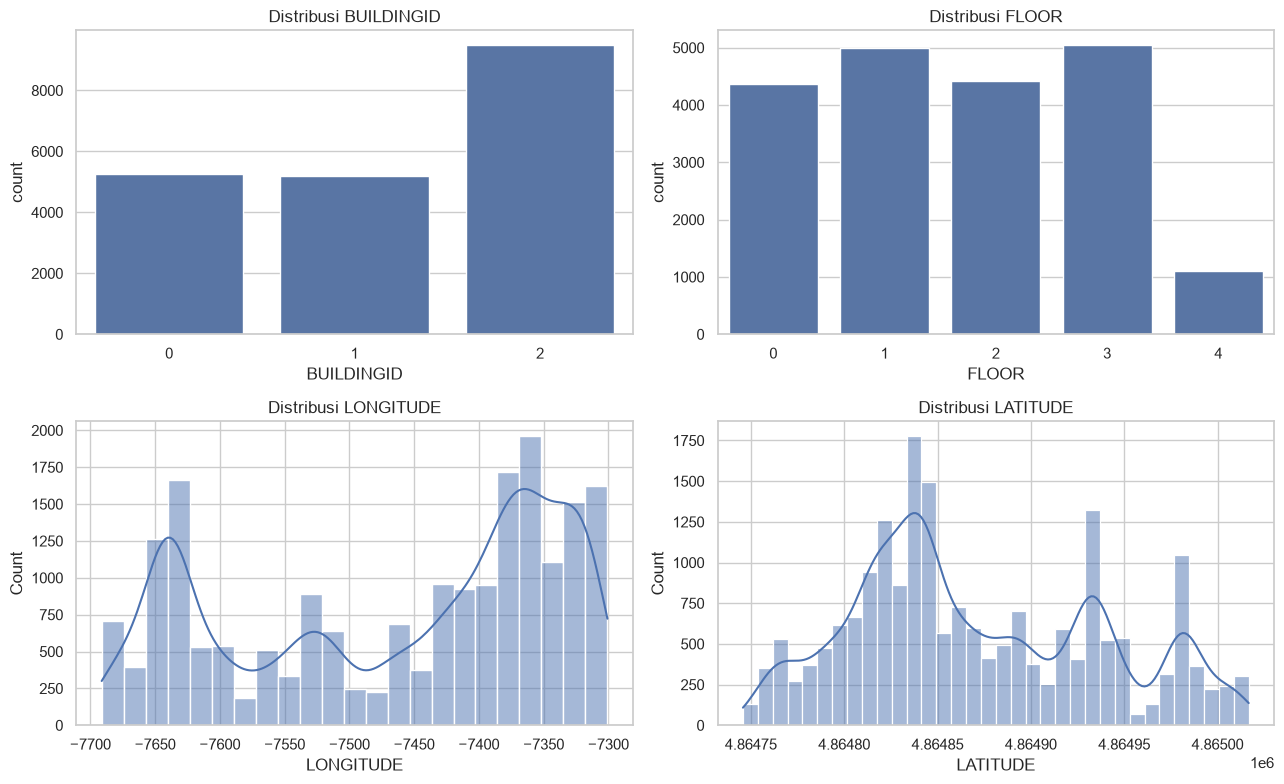

,BUILDINGID,FLOOR,LONGITUDE,LATITUDE
count,19937.000000,19937.000000,19937.000000,1.993700e+04
mean,1.212820,1.674575,-7464.275947,4.864871e+06
std,0.833139,1.223078,123.402010,6.693318e+01
min,0.000000,0.000000,-7691.338400,4.864746e+06
25%,0.000000,1.000000,-7594.737000,4.864821e+06
50%,1.000000,2.000000,-7423.060900,4.864852e+06
75%,2.000000,3.000000,-7359.193000,4.864930e+06
max,2.000000,4.000000,-7300.818990,4.865017e+06


In [15]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
sns.countplot(data=train_df, x="BUILDINGID", ax=axes[0, 0])
axes[0, 0].set_title("Distribusi BUILDINGID")
sns.countplot(data=train_df, x="FLOOR", ax=axes[0, 1])
axes[0, 1].set_title("Distribusi FLOOR")
sns.histplot(train_df["LONGITUDE"], kde=True, ax=axes[1, 0])
axes[1, 0].set_title("Distribusi LONGITUDE")
sns.histplot(train_df["LATITUDE"], kde=True, ax=axes[1, 1])
axes[1, 1].set_title("Distribusi LATITUDE")
plt.tight_layout()
plt.show()

display(train_df[TARGET_COLS].describe())

### Cell 5B. Membandingkan distribusi training dan validation
Cell ini memastikan kedua file memiliki struktur target yang sebanding. Validation hanya diperiksa secara deskriptif. Data ini belum digunakan untuk menentukan parameter preprocessing.

In [16]:
for name, data in [("Training", train_df), ("Validation", validation_df)]:
    print(f"--- {name} ---")
    print("Shape:", data.shape)
    print("BUILDINGID:")
    display(data["BUILDINGID"].value_counts().sort_index())
    print("FLOOR:")
    display(data["FLOOR"].value_counts().sort_index())
    display(data[["LONGITUDE", "LATITUDE"]].describe())

--- Training ---
Shape: (19937, 529)
BUILDINGID:


BUILDINGID
0    5249
1    5196
2    9492
Name: count, dtype: int64

FLOOR:


FLOOR
0    4369
1    5002
2    4416
3    5048
4    1102
Name: count, dtype: int64

,LONGITUDE,LATITUDE
count,19937.000000,1.993700e+04
mean,-7464.275947,4.864871e+06
std,123.402010,6.693318e+01
min,-7691.338400,4.864746e+06
25%,-7594.737000,4.864821e+06
50%,-7423.060900,4.864852e+06
75%,-7359.193000,4.864930e+06
max,-7300.818990,4.865017e+06


--- Validation ---
Shape: (1111, 529)
BUILDINGID:


BUILDINGID
0    536
1    307
2    268
Name: count, dtype: int64

FLOOR:


FLOOR
0    132
1    462
2    306
3    172
4     39
Name: count, dtype: int64

,LONGITUDE,LATITUDE
count,1111.000000,1.111000e+03
mean,-7529.197448,4.864902e+06
std,120.209336,7.027280e+01
min,-7695.938755,4.864748e+06
25%,-7637.423800,4.864843e+06
50%,-7560.376300,4.864915e+06
75%,-7420.539659,4.864967e+06
max,-7299.786517,4.865017e+06


### Cell 6. Menghitung detection rate WAP
Detection rate menunjukkan proporsi baris ketika suatu WAP terdeteksi. Perhitungan dilakukan sebelum nilai `100` diganti agar nilai imputasi tidak salah dihitung sebagai sinyal terdeteksi.

,detection_rate,detection_percent
WAP496,0.238250,23.825049
WAP087,0.234388,23.438832
WAP502,0.232583,23.258264
WAP517,0.227868,22.786778
WAP078,0.224658,22.465767
WAP248,0.220394,22.039424
WAP077,0.218789,21.878919
WAP070,0.209811,20.981090
WAP062,0.209008,20.900838
WAP069,0.202889,20.288910


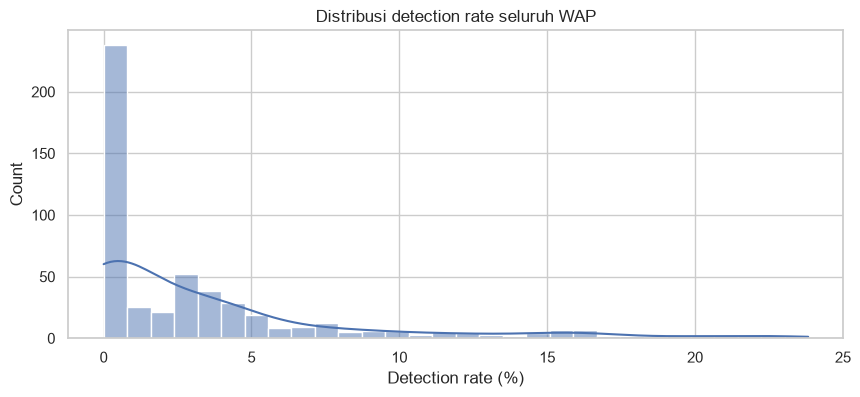

In [17]:
detection_rate = train_df[wap_cols].ne(100).mean().sort_values(ascending=False)
detection_table = pd.DataFrame({
    "detection_rate": detection_rate,
    "detection_percent": detection_rate * 100
})
display(detection_table.head(20))

plt.figure(figsize=(10, 4))
sns.histplot(detection_table["detection_percent"], bins=30, kde=True)
plt.xlabel("Detection rate (%)")
plt.title("Distribusi detection rate seluruh WAP")
plt.show()

### Cell 7. Melihat distribusi RSSI
Cell ini menampilkan distribusi RSSI pada beberapa WAP yang paling sering terdeteksi. Nilai sentinel `100` diubah menjadi NaN hanya untuk visualisasi agar tidak merusak skala RSSI.

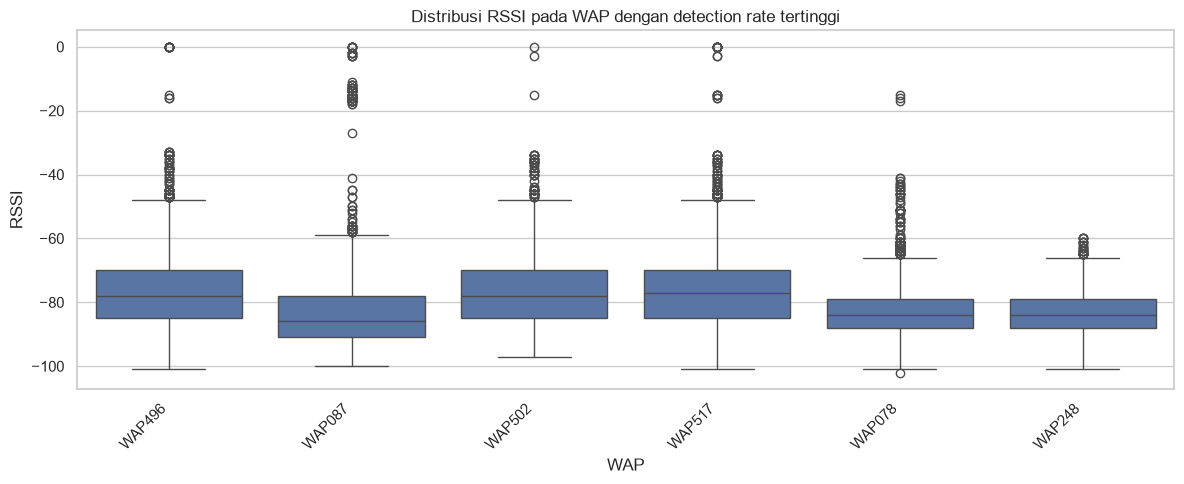

In [18]:
selected_for_plot = detection_table.head(min(6, len(detection_table))).index.tolist()
rssi_long = train_df[selected_for_plot].replace(100, np.nan).melt(
    var_name="WAP", value_name="RSSI"
).dropna()

plt.figure(figsize=(12, 5))
sns.boxplot(data=rssi_long, x="WAP", y="RSSI")
plt.xticks(rotation=45, ha="right")
plt.title("Distribusi RSSI pada WAP dengan detection rate tertinggi")
plt.tight_layout()
plt.show()

### Cell 8. Analisis korelasi
Cell ini melihat hubungan linear antara beberapa WAP yang sering terdeteksi dan target. Heatmap dibatasi pada 25 WAP agar tetap mudah dibaca. Korelasi bukan bukti hubungan sebab-akibat.

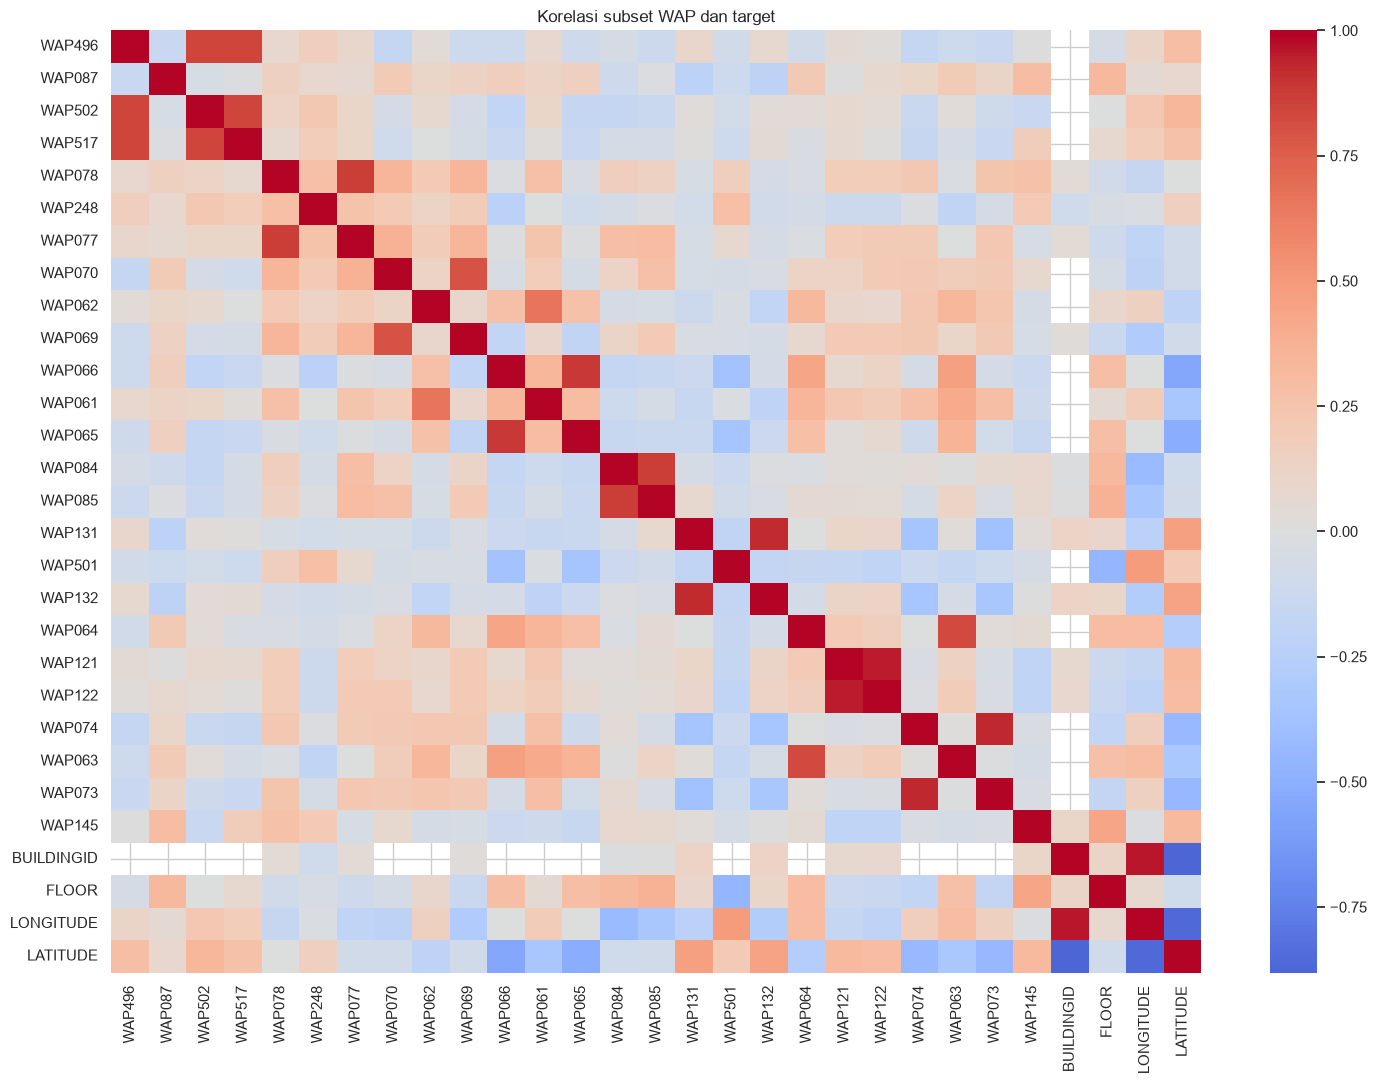

In [19]:
eda_corr = train_df[wap_cols + TARGET_COLS].copy()
eda_corr[wap_cols] = eda_corr[wap_cols].replace(100, np.nan)
top_waps = detection_table.head(min(25, len(detection_table))).index.tolist()
corr_matrix = eda_corr[top_waps + TARGET_COLS].corr(numeric_only=True)

plt.figure(figsize=(15, 11))
sns.heatmap(corr_matrix, cmap="coolwarm", center=0)
plt.title("Korelasi subset WAP dan target")
plt.tight_layout()
plt.show()

### Cell 9. Pemeriksaan outlier koordinat
Cell ini memakai aturan IQR dan boxplot untuk menandai kandidat outlier pada koordinat. Outlier tidak langsung dihapus karena koordinat ekstrem bisa saja merupakan lokasi pengukuran yang valid.

,Q1,Q3,IQR,batas_bawah,batas_atas,jumlah_kandidat_outlier,persentase
LONGITUDE,-7.594737e+03,-7.359193e+03,235.544,-7.948053e+03,-7.005877e+03,0.0,0.0
LATITUDE,4.864821e+06,4.864930e+06,109.015,4.864657e+06,4.865093e+06,0.0,0.0


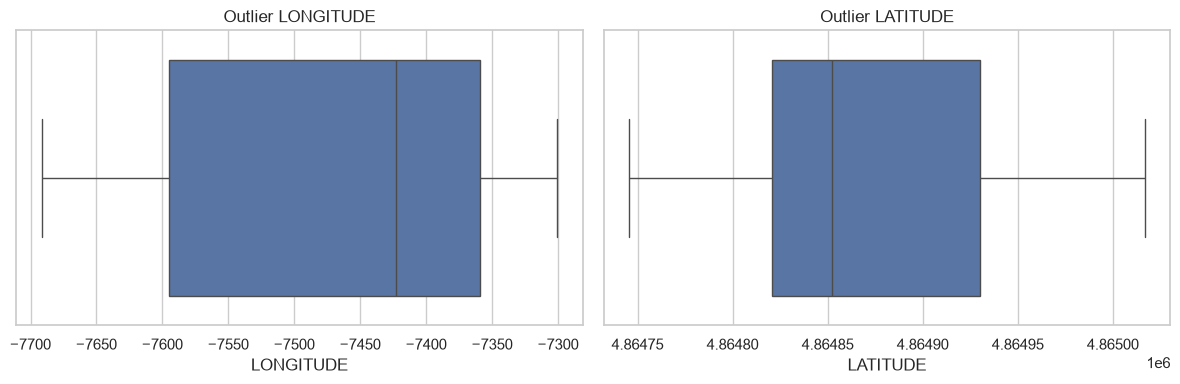

In [20]:
def get_iqr_report(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (series < lower) | (series > upper)
    return {
        "Q1": q1, "Q3": q3, "IQR": iqr,
        "batas_bawah": lower, "batas_atas": upper,
        "jumlah_kandidat_outlier": int(mask.sum()),
        "persentase": mask.mean() * 100
    }

display(pd.DataFrame({
    col: get_iqr_report(train_df[col]) for col in ["LONGITUDE", "LATITUDE"]
}).T)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=train_df["LONGITUDE"], ax=axes[0])
axes[0].set_title("Outlier LONGITUDE")
sns.boxplot(x=train_df["LATITUDE"], ax=axes[1])
axes[1].set_title("Outlier LATITUDE")
plt.tight_layout()
plt.show()

### Cell 10. Memisahkan fitur, target, dan metadata
Kolom target dan metadata dikeluarkan dari fitur. Pemisahan ini mencegah target atau informasi identitas pengguna/perangkat ikut memengaruhi preprocessing dan clustering.

In [21]:
excluded_cols = set(TARGET_COLS + METADATA_COLS)
feature_cols = [c for c in train_df.columns if c not in excluded_cols]

X_all = train_df[feature_cols].copy()
print("Jumlah fitur prediktor:", X_all.shape[1])
print("Jumlah fitur WAP:", len([c for c in feature_cols if c in wap_cols]))
print("Kolom yang dikeluarkan:", [c for c in train_df.columns if c in excluded_cols])

Jumlah fitur prediktor: 522
Jumlah fitur WAP: 520
Kolom yang dikeluarkan: ['LONGITUDE', 'LATITUDE', 'FLOOR', 'BUILDINGID', 'USERID', 'PHONEID', 'TIMESTAMP']


### Cell 11. Membagi data training dan testing internal
Pembagian internal 80:20 disiapkan untuk analisis lanjutan yang membutuhkan evaluasi. Stratifikasi menggunakan BUILDINGID. Dataset test tidak dipakai untuk mempelajari parameter preprocessing.

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X_all, train_df[TARGET_COLS],
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=train_df["BUILDINGID"]
)
print("Data train:", X_train.shape)
print("Data test:", X_test.shape)
display(pd.DataFrame({
    "train": y_train["BUILDINGID"].value_counts(normalize=True).sort_index(),
    "test": y_test["BUILDINGID"].value_counts(normalize=True).sort_index()
}))

Data train: (15949, 522)
Data test: (3988, 522)


,train,test
BUILDINGID,,
0,0.263277,0.263290
1,0.260643,0.260532
2,0.476080,0.476179


### Cell 12. Membandingkan metode penanganan nilai tidak terdeteksi
Dua metode dibandingkan: (1) imputasi median dan (2) imputasi konstanta -105. Nilai 100 diubah menjadi NaN terlebih dahulu. Imputer hanya di-fit pada training set agar tidak terjadi data leakage.

In [23]:
Xtr_wap = X_train[wap_cols].replace(100, np.nan)
Xte_wap = X_test[wap_cols].replace(100, np.nan)

median_imputer = SimpleImputer(strategy="median")
Xtr_median = median_imputer.fit_transform(Xtr_wap)
Xte_median = median_imputer.transform(Xte_wap)

constant_imputer = SimpleImputer(strategy="constant", fill_value=-105)
Xtr_constant = constant_imputer.fit_transform(Xtr_wap)
Xte_constant = constant_imputer.transform(Xte_wap)

imputation_comparison = pd.DataFrame({
    "metode": ["Median", "Konstanta -105"],
    "NaN_train_setelah_imputasi": [
        int(np.isnan(Xtr_median).sum()),
        int(np.isnan(Xtr_constant).sum())
    ],
    "rata_rata_train": [Xtr_median.mean(), Xtr_constant.mean()],
    "standar_deviasi_train": [Xtr_median.std(), Xtr_constant.std()]
})
display(imputation_comparison)

,metode,NaN_train_setelah_imputasi,rata_rata_train,standar_deviasi_train
0,Median,0,-84.056172,7.479769
1,Konstanta -105,0,-103.965241,5.706082


### Cell 13. Memeriksa class imbalance
Cell ini memeriksa distribusi BUILDINGID dan FLOOR pada data training. Hasilnya membantu menentukan apakah distribusi kelas tidak seimbang. Karena clustering tidak membutuhkan label kelas, informasi ini terutama berguna untuk analisis dan evaluasi interpretatif.

,jumlah,persentase
BUILDINGID,,
0,4199,26.33
1,4157,26.06
2,7593,47.61


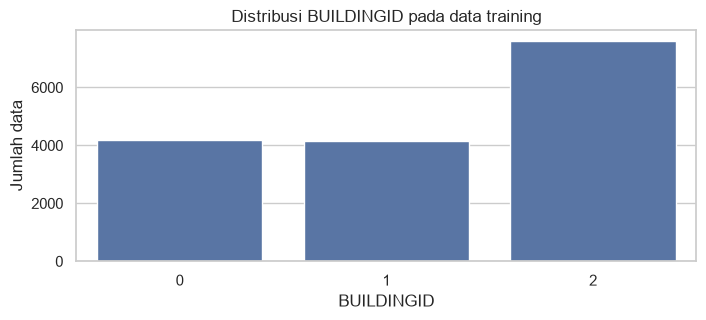

Rasio kelas terbesar/terkecil: 1.83


,jumlah,persentase
FLOOR,,
0,3505,21.98
1,4026,25.24
2,3522,22.08
3,4026,25.24
4,870,5.45


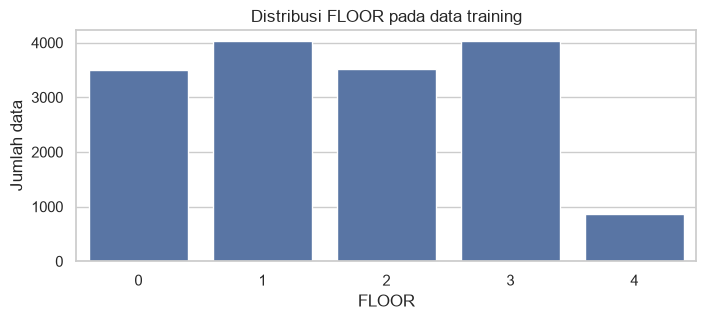

Rasio kelas terbesar/terkecil: 4.63


In [24]:
for target in ["BUILDINGID", "FLOOR"]:
    counts = y_train[target].value_counts().sort_index()
    display(pd.DataFrame({
        "jumlah": counts,
        "persentase": (counts / counts.sum() * 100).round(2)
    }))
    plt.figure(figsize=(8, 3))
    sns.barplot(x=counts.index.astype(str), y=counts.values)
    plt.title(f"Distribusi {target} pada data training")
    plt.xlabel(target)
    plt.ylabel("Jumlah data")
    plt.show()
    print("Rasio kelas terbesar/terkecil:", round(counts.max()/counts.min(), 2))

### Cell 14. Seleksi fitur WAP berdasarkan detection rate
WAP dengan detection rate minimal 5% dipilih sebagai subset awal. Seleksi ini mengurangi fitur yang hampir selalu tidak terdeteksi. Detection rate dihitung dari training set saja.

Jumlah WAP awal: 520
Jumlah WAP terpilih: 114
Jumlah WAP yang tidak dipilih: 406


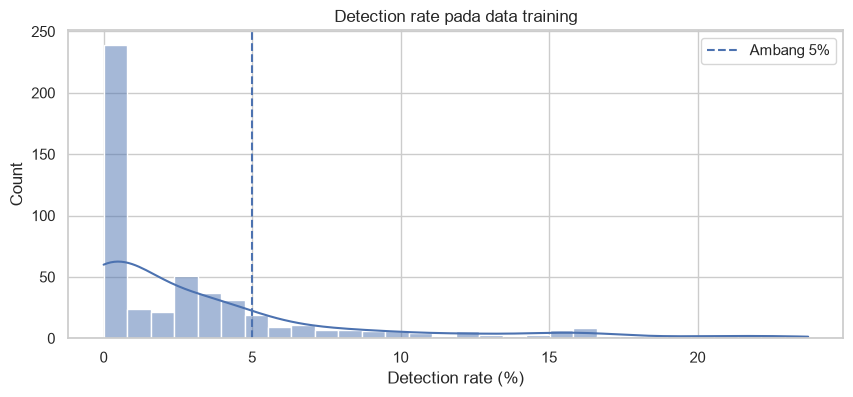

In [25]:
train_detection_rate = X_train[wap_cols].ne(100).mean()
selected_waps = train_detection_rate[train_detection_rate >= 0.05].index.tolist()

print("Jumlah WAP awal:", len(wap_cols))
print("Jumlah WAP terpilih:", len(selected_waps))
print("Jumlah WAP yang tidak dipilih:", len(wap_cols) - len(selected_waps))

plt.figure(figsize=(10, 4))
sns.histplot(train_detection_rate * 100, bins=30, kde=True)
plt.axvline(5, linestyle="--", label="Ambang 5%")
plt.xlabel("Detection rate (%)")
plt.title("Detection rate pada data training")
plt.legend()
plt.show()

### Cell 15. Membentuk data hasil preprocessing
Untuk clustering, notebook memakai fitur WAP terpilih. Nilai sentinel 100 diubah menjadi NaN, lalu diimputasi dengan konstanta -105. Setelah itu fitur distandardisasi. Imputer dan scaler di-fit pada data training saja.

In [26]:
if len(selected_waps) == 0:
    raise ValueError("Tidak ada fitur WAP yang memenuhi ambang detection rate. Periksa data/ambang.")

cluster_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value=-105)),
    ("scaler", StandardScaler())
])

X_train_cluster_raw = X_train[selected_waps].replace(100, np.nan)
X_test_cluster_raw = X_test[selected_waps].replace(100, np.nan)

X_train_cluster = cluster_preprocessor.fit_transform(X_train_cluster_raw)
X_test_cluster = cluster_preprocessor.transform(X_test_cluster_raw)

print("Matriks clustering train:", X_train_cluster.shape)
print("Matriks clustering test:", X_test_cluster.shape)
print("NaN tersisa:", int(np.isnan(X_train_cluster).sum()))

Matriks clustering train: (15949, 114)
Matriks clustering test: (3988, 114)
NaN tersisa: 0


## PROSES 2 — CLUSTERING

### Cell 16. Menyiapkan data clustering
Clustering dilakukan pada data training yang sudah dipreproses. Label target tidak dimasukkan sebagai fitur. Kita menyimpan target terpisah hanya untuk melihat apakah cluster yang terbentuk memiliki pola gedung atau lantai tertentu.

In [27]:
X_cluster = X_train_cluster
cluster_reference = y_train.reset_index(drop=True).copy()

print("Jumlah sampel untuk clustering:", X_cluster.shape[0])
print("Jumlah fitur untuk clustering:", X_cluster.shape[1])

Jumlah sampel untuk clustering: 15949
Jumlah fitur untuk clustering: 114


### Cell 17. Menentukan jumlah cluster dengan Elbow Method
K-Means memerlukan jumlah cluster (`k`). Elbow Method membandingkan inertia untuk beberapa nilai k. Titik siku dapat menjadi kandidat jumlah cluster, tetapi tetap perlu dipertimbangkan bersama metrik lain dan tujuan analisis.

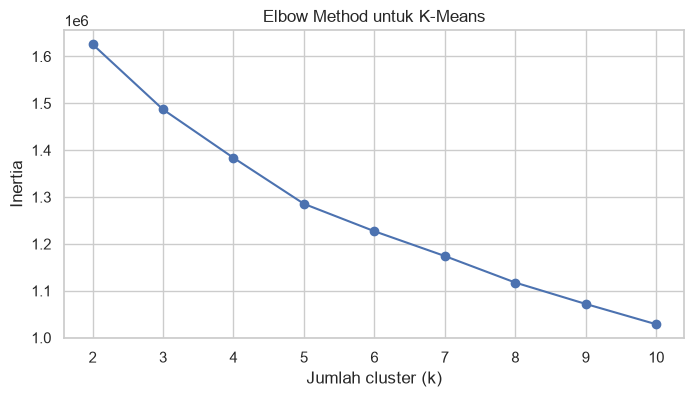

In [28]:
inertias = []
k_values = range(2, 11)

for k in k_values:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    km.fit(X_cluster)
    inertias.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Jumlah cluster (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method untuk K-Means")
plt.xticks(list(k_values))
plt.show()

### Cell 18. Melatih K-Means
Ganti `BEST_K` berdasarkan hasil Elbow Method dan pertimbangan analisis. Cell ini melatih K-Means dan menyimpan label cluster untuk setiap baris data training.

In [29]:
BEST_K = 4  # Ubah setelah mengamati grafik Elbow Method

kmeans = KMeans(n_clusters=BEST_K, random_state=RANDOM_STATE, n_init=10)
kmeans_labels = kmeans.fit_predict(X_cluster)

print("Jumlah anggota tiap cluster:")
display(pd.Series(kmeans_labels, name="cluster").value_counts().sort_index())

Jumlah anggota tiap cluster:


cluster
0    1905
1    5822
2    6370
3    1852
Name: count, dtype: int64

### Cell 18B. Menerapkan preprocessing dan K-Means ke validation data
Scaler dan imputasi tidak di-fit ulang. Validation ditransformasi memakai preprocessing hasil fit training, lalu K-Means memberikan label cluster melalui `predict()`. Ini menguji apakah pola cluster training dapat diterapkan pada data baru.

In [30]:
# Gunakan hanya fitur WAP yang dipilih pada training
X_validation_cluster_raw = validation_df[selected_waps].replace(100, np.nan)

# Transform memakai imputer + scaler yang sudah fit pada training
X_validation_cluster = cluster_preprocessor.transform(X_validation_cluster_raw)

# Assign cluster validation menggunakan centroid K-Means hasil training
validation_kmeans_labels = kmeans.predict(X_validation_cluster)

validation_cluster_result = validation_df[TARGET_COLS].copy()
validation_cluster_result["KMEANS_CLUSTER"] = validation_kmeans_labels

print("Ukuran validation setelah preprocessing:", X_validation_cluster.shape)
print("Distribusi cluster validation:")
display(validation_cluster_result["KMEANS_CLUSTER"].value_counts().sort_index())
display(pd.crosstab(validation_cluster_result["KMEANS_CLUSTER"],
                    validation_cluster_result["BUILDINGID"], normalize="index").round(3))

Ukuran validation setelah preprocessing: (1111, 114)
Distribusi cluster validation:


KMEANS_CLUSTER
0    194
1    206
2    483
3    228
Name: count, dtype: int64

BUILDINGID,0,1,2
KMEANS_CLUSTER,,,
0,1.000,0.000,0.000
1,0.000,0.000,1.000
2,0.236,0.636,0.128
3,1.000,0.000,0.000


### Cell 19. Evaluasi K-Means
Silhouette Score mengukur kekompakan dan pemisahan cluster. Davies-Bouldin Index mengukur kemiripan antarcluster. Silhouette lebih tinggi umumnya lebih baik, sedangkan Davies-Bouldin lebih rendah umumnya lebih baik. Skor dihitung pada sampel bila dataset terlalu besar.

In [31]:
rng = np.random.default_rng(RANDOM_STATE)
eval_n = min(5000, len(X_cluster))
eval_idx = rng.choice(len(X_cluster), size=eval_n, replace=False)

sil_kmeans = silhouette_score(X_cluster[eval_idx], kmeans_labels[eval_idx])
db_kmeans = davies_bouldin_score(X_cluster[eval_idx], kmeans_labels[eval_idx])

print("Silhouette K-Means:", round(sil_kmeans, 4))
print("Davies-Bouldin K-Means:", round(db_kmeans, 4))

Silhouette K-Means: 0.127
Davies-Bouldin K-Means: 2.2738


### Cell 20. Reduksi dimensi dengan PCA
PCA merangkum fitur menjadi dua komponen agar cluster dapat divisualisasikan. PCA di sini digunakan untuk visualisasi, bukan menggantikan data fitur asli yang dipakai K-Means.

Variansi yang dijelaskan PC1 dan PC2: [0.1375 0.0864]
Total variansi dua komponen: 0.2239


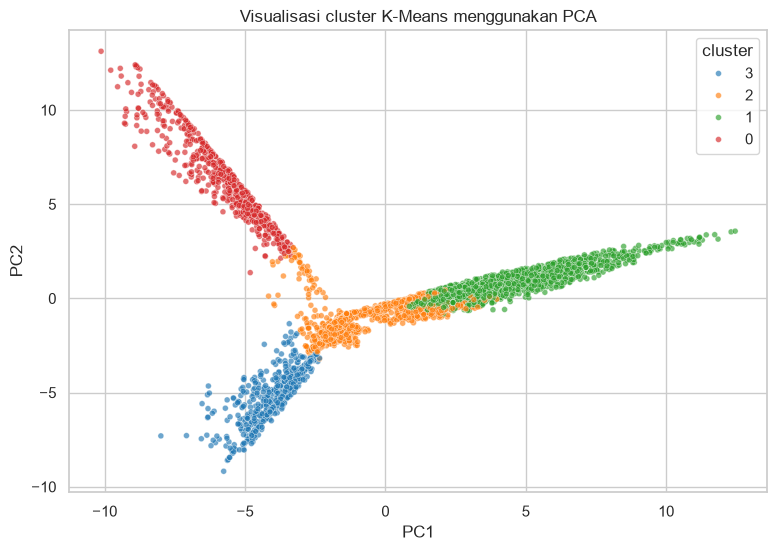

In [32]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_cluster)

print("Variansi yang dijelaskan PC1 dan PC2:",
      np.round(pca.explained_variance_ratio_, 4))
print("Total variansi dua komponen:",
      round(pca.explained_variance_ratio_.sum(), 4))

plot_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "cluster": kmeans_labels.astype(str)
})

plt.figure(figsize=(9, 6))
sns.scatterplot(data=plot_df.sample(min(5000, len(plot_df)),
                                   random_state=RANDOM_STATE),
                x="PC1", y="PC2", hue="cluster", palette="tab10",
                s=18, alpha=0.65)
plt.title("Visualisasi cluster K-Means menggunakan PCA")
plt.show()

### Cell 21. Membandingkan cluster dengan BUILDINGID dan FLOOR
Label gedung dan lantai tidak digunakan untuk membentuk cluster. Tabel silang ini hanya membantu interpretasi setelah clustering, misalnya melihat apakah cluster cenderung berisi data dari gedung atau lantai tertentu.

In [33]:
interpretation = cluster_reference.copy()
interpretation["cluster"] = kmeans_labels
print("Cluster vs BUILDINGID:")
display(pd.crosstab(interpretation["cluster"],
                    interpretation["BUILDINGID"], normalize="index").round(3))
print("Cluster vs FLOOR:")
display(pd.crosstab(interpretation["cluster"],
                    interpretation["FLOOR"], normalize="index").round(3))

Cluster vs BUILDINGID:


BUILDINGID,0,1,2
cluster,,,
0,1.000,0.000,0.000
1,0.000,0.000,1.000
2,0.069,0.653,0.278
3,1.000,0.000,0.000


Cluster vs FLOOR:


FLOOR,0,1,2,3,4
cluster,,,,,
0,0.200,0.271,0.273,0.256,0.000
1,0.166,0.222,0.170,0.301,0.141
2,0.299,0.268,0.228,0.197,0.007
3,0.135,0.278,0.301,0.286,0.000


### Cell 22. Menyiapkan parameter DBSCAN dengan k-distance plot
DBSCAN tidak perlu menentukan jumlah cluster di awal. DBSCAN memerlukan `eps` dan `min_samples`. Grafik jarak ke tetangga ke-k membantu memperkirakan kandidat `eps`. Gunakan sampel agar proses lebih ringan.

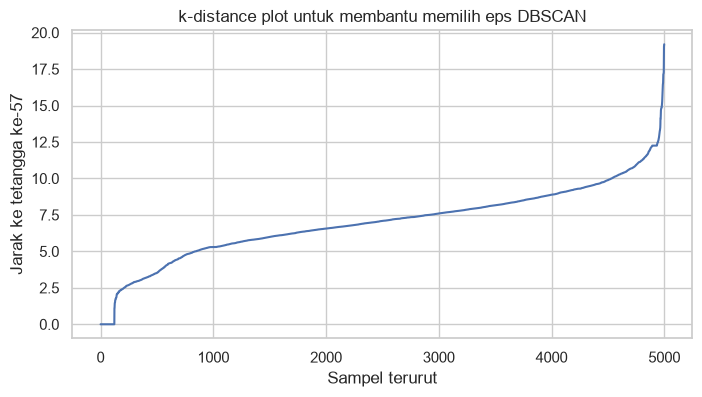

MIN_SAMPLES kandidat: 57
Tentukan EPS berdasarkan titik perubahan kemiringan pada grafik.


In [34]:
dbscan_sample_n = min(5000, len(X_cluster))
dbscan_rng = np.random.default_rng(RANDOM_STATE)
dbscan_idx = dbscan_rng.choice(len(X_cluster), size=dbscan_sample_n, replace=False)
X_dbscan_sample = X_cluster[dbscan_idx]

MIN_SAMPLES = max(5, X_cluster.shape[1] // 2)
neighbors = NearestNeighbors(n_neighbors=MIN_SAMPLES)
neighbors.fit(X_dbscan_sample)
distances, _ = neighbors.kneighbors(X_dbscan_sample)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(8, 4))
plt.plot(k_distances)
plt.xlabel("Sampel terurut")
plt.ylabel(f"Jarak ke tetangga ke-{MIN_SAMPLES}")
plt.title("k-distance plot untuk membantu memilih eps DBSCAN")
plt.show()

print("MIN_SAMPLES kandidat:", MIN_SAMPLES)
print("Tentukan EPS berdasarkan titik perubahan kemiringan pada grafik.")

### Cell 23. Menjalankan DBSCAN pada sampel
DBSCAN dapat membutuhkan komputasi besar pada dataset berdimensi tinggi. Karena itu, contoh ini dijalankan pada sampel training. Atur `EPS` berdasarkan k-distance plot. Label `-1` berarti noise atau data yang tidak masuk cluster.

**Catatan validation:** DBSCAN tidak menyediakan `predict()` bawaan. Karena itu, notebook menggunakan validation untuk penugasan cluster K-Means. Untuk DBSCAN, validasi memerlukan metode tambahan seperti aturan tetangga/representatif cluster dan harus dijelaskan sebagai pendekatan, bukan prediksi native DBSCAN.

In [35]:
EPS = 5.0  # Sesuaikan berdasarkan k-distance plot, jangan anggap nilai ini selalu optimal

dbscan = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES, n_jobs=-1)
dbscan_labels = dbscan.fit_predict(X_dbscan_sample)

dbscan_counts = pd.Series(dbscan_labels, name="cluster").value_counts().sort_index()
display(dbscan_counts)
n_clusters_dbscan = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise = int(np.sum(dbscan_labels == -1))
print("Jumlah cluster DBSCAN (tanpa noise):", n_clusters_dbscan)
print("Jumlah noise:", n_noise)
print("Persentase noise:", round(n_noise / len(dbscan_labels) * 100, 2), "%")

cluster
-1    3388
 0    1341
 1      90
 2      66
 3      55
 4      60
Name: count, dtype: int64

Jumlah cluster DBSCAN (tanpa noise): 5
Jumlah noise: 3388
Persentase noise: 67.76 %


### Cell 24. Evaluasi DBSCAN
Metrik silhouette dan Davies-Bouldin dihitung hanya jika DBSCAN menghasilkan minimal dua cluster non-noise. Noise dikeluarkan dari penghitungan metrik agar label noise tidak dianggap sebagai satu cluster biasa.

In [36]:
valid_mask = dbscan_labels != -1
valid_labels = dbscan_labels[valid_mask]
valid_data = X_dbscan_sample[valid_mask]

if len(np.unique(valid_labels)) >= 2 and len(valid_data) > 2:
    score_n = min(3000, len(valid_data))
    score_rng = np.random.default_rng(RANDOM_STATE)
    score_idx = score_rng.choice(len(valid_data), size=score_n, replace=False)
    print("Silhouette DBSCAN:",
          round(silhouette_score(valid_data[score_idx],
                                 valid_labels[score_idx]), 4))
    print("Davies-Bouldin DBSCAN:",
          round(davies_bouldin_score(valid_data[score_idx],
                                     valid_labels[score_idx]), 4))
else:
    print("Metrik internal tidak dihitung: DBSCAN tidak menghasilkan minimal dua cluster non-noise.")

Silhouette DBSCAN: 0.2522
Davies-Bouldin DBSCAN: 1.081


### Cell 25. Visualisasi hasil DBSCAN dengan PCA
PCA dua dimensi digunakan untuk melihat persebaran hasil DBSCAN pada sampel. Warna `-1` menunjukkan noise. Visualisasi ini membantu pemeriksaan pola, tetapi tidak menjadi satu-satunya dasar penilaian kualitas cluster.

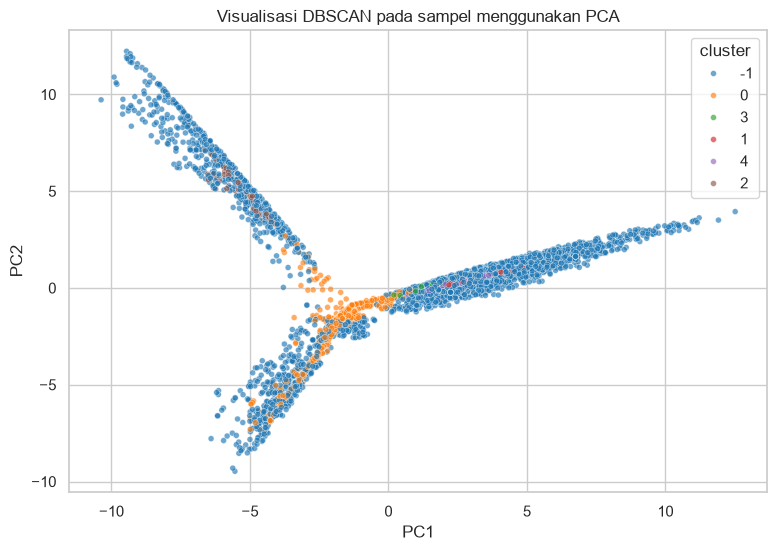

In [37]:
X_dbscan_pca = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_dbscan_sample)
dbscan_plot = pd.DataFrame({
    "PC1": X_dbscan_pca[:, 0],
    "PC2": X_dbscan_pca[:, 1],
    "cluster": dbscan_labels.astype(str)
})

plt.figure(figsize=(9, 6))
sns.scatterplot(data=dbscan_plot, x="PC1", y="PC2",
                hue="cluster", s=18, alpha=0.65, palette="tab10")
plt.title("Visualisasi DBSCAN pada sampel menggunakan PCA")
plt.show()

### Cell 26. Menyimpan hasil clustering
Cell ini menyimpan label K-Means untuk seluruh data training dan label DBSCAN untuk sampel yang digunakan. File hasil dapat dipakai untuk analisis lanjutan dan pelaporan.

In [38]:
kmeans_result = cluster_reference.copy()
kmeans_result["KMEANS_CLUSTER"] = kmeans_labels
kmeans_result.to_csv("hasil_kmeans_training.csv", index=False)

dbscan_result = cluster_reference.iloc[dbscan_idx].copy().reset_index(drop=True)
dbscan_result["DBSCAN_CLUSTER"] = dbscan_labels
dbscan_result.to_csv("hasil_dbscan_sample.csv", index=False)

print("File tersimpan:")
print("- hasil_kmeans_training.csv")
print("- hasil_dbscan_sample.csv")

validation_cluster_result.to_csv("hasil_kmeans_validation.csv", index=False)
print("- hasil_kmeans_validation.csv")

File tersimpan:
- hasil_kmeans_training.csv
- hasil_dbscan_sample.csv
- hasil_kmeans_validation.csv


## Ringkasan akhir

**Proses 1** melakukan EDA, pemeriksaan kualitas data, penanganan sentinel, pemeriksaan outlier, pembagian data, perbandingan imputasi, pemeriksaan distribusi kelas, seleksi fitur, dan scaling.

**Proses 2** melakukan clustering dengan K-Means dan DBSCAN. K-Means dievaluasi dengan Elbow Method, Silhouette Score, dan Davies-Bouldin Index. DBSCAN dijalankan pada sampel agar komputasinya lebih terkendali.

### Hal yang perlu diperhatikan saat interpretasi
- Nilai `EPS` DBSCAN dan `BEST_K` K-Means perlu ditentukan berdasarkan grafik dan hasil evaluasi, bukan diterima begitu saja dari nilai awal.
- Clustering tidak menggunakan BUILDINGID, FLOOR, LONGITUDE, atau LATITUDE sebagai fitur.
- Silhouette dan Davies-Bouldin hanya mengukur kualitas struktur cluster, bukan akurasi prediksi lokasi.
- Hasil clustering dapat dibandingkan dengan BUILDINGID dan FLOOR setelah proses selesai untuk membantu interpretasi.
- Periksa sistem koordinat sebelum mengartikan selisih LONGITUDE/LATITUDE sebagai jarak dalam meter.